# Sweep A — two parallel strips in the challenge box (step 5)

Reads the CSV files written by `exploration_sweep.py` (no computation here) and draws:

1. G, D and G_max (dBi) vs spacing d, one curve per f0 (α_cal, best configuration; shaded: α_cal × (0.85 … 1.15));
2. η_rad vs d;
3. optimal load reactance vs d (director and reflector configurations);
4. G vs f around f0 for the best points, with the loads frozen as L or C.

Target: gain G with ideal matching towards +y, φ polarisation. Loss model: `backend.optim.loss_model` (empirical α calibrated on CST V5b′,
n_width = 4 cosine rule). Data folder: `EXPLORATION_DIR` environment variable, else the PUBLICATIONS `exploration/` folder.

In [1]:
%matplotlib inline
import csv, json, os
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

DATA_DIR = Path(os.environ.get('EXPLORATION_DIR', r'D:\PhD_Fahdilou_Leat\PUBLICATIONS\7-EurAAP Small Antenna Super-Gain Challenge\exploration'))
FIG_DIR = DATA_DIR / 'figures'
FIG_DIR.mkdir(parents=True, exist_ok=True)

def read_rows(path):
    def num(v):
        try:
            return float(v)
        except ValueError:
            return {'True': True, 'False': False}.get(v, v)
    with open(path, newline='', encoding='utf-8') as fh:
        return [{k: num(v) for k, v in r.items()} for r in csv.DictReader(fh)]

sweeps = {}
for p in sorted(DATA_DIR.glob('sweepA_w*mm.csv')):
    tag = p.stem
    sens = p.with_name(tag + '_sensitivity.csv')
    meta = p.with_name(tag + '_meta.json')
    sweeps[tag] = dict(rows=read_rows(p), sens=read_rows(sens) if sens.exists() else [],
                       meta=json.loads(meta.read_text(encoding='utf-8')) if meta.exists() else {})
    print(f"{tag}: {len(sweeps[tag]['rows'])} rows, {len(sweeps[tag]['sens'])} sensitivity rows")

# Chart style (reference palette of the dataviz method, light mode)
INK, INK_2, MUTED, GRID, AXIS, SURFACE = '#0b0b0b', '#52514e', '#898781', '#e1e0d9', '#c3c2b7', '#fcfcfb'
SERIES = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100']
plt.rcParams.update({'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE, 'savefig.facecolor': SURFACE,
                     'axes.edgecolor': AXIS, 'axes.labelcolor': INK_2, 'xtick.color': MUTED, 'ytick.color': MUTED,
                     'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.6, 'axes.spines.top': False,
                     'axes.spines.right': False, 'lines.linewidth': 1.6, 'legend.frameon': False,
                     'font.size': 9, 'axes.titlesize': 10, 'figure.dpi': 110})

def save(fig, name, ncol=3):
    """Shared legend below the plots, PNG saved in FIG_DIR, and the figure shown in the notebook."""
    handles, labels = [], []
    for ax in fig.axes:
        for h, l in zip(*ax.get_legend_handles_labels()):
            if l not in labels:
                handles.append(h); labels.append(l)
    if labels:
        fig.legend(handles, labels, loc='lower center', ncol=ncol)
        rows = int(np.ceil(len(labels) / ncol))
        fig.tight_layout(rect=(0, min(0.35, 0.05 + 0.045 * rows), 1, 1))
    else:
        fig.tight_layout()
    fig.savefig(FIG_DIR / name, dpi=150)
    print('saved', FIG_DIR / name)
    plt.show()

def select(rows, **kw):
    return [r for r in rows if all(abs(r[k] - v) < 1e-9 if isinstance(v, float) else r[k] == v for k, v in kw.items())]

def best_curve(rows, f, factor, key):
    """(d, value) of the best configuration at each spacing, for f0 = f and alpha = factor * alpha_cal."""
    ds = sorted({r['spacing_mm'] for r in rows})
    pts = []
    for d in ds:
        g = select(rows, spacing_mm=d, f_GHz=f, alpha_factor=factor)
        if g:
            b = max(g, key=lambda r: r['G'])
            pts.append((d, b[key]))
    return np.array(pts).T if pts else (np.array([]), np.array([]))

sweepA_w4mm: 198 rows, 15 sensitivity rows


saved D:\PhD_Fahdilou_Leat\PUBLICATIONS\7-EurAAP Small Antenna Super-Gain Challenge\exploration\figures\sweepA_w4mm_G_D_Gmax_vs_d.png


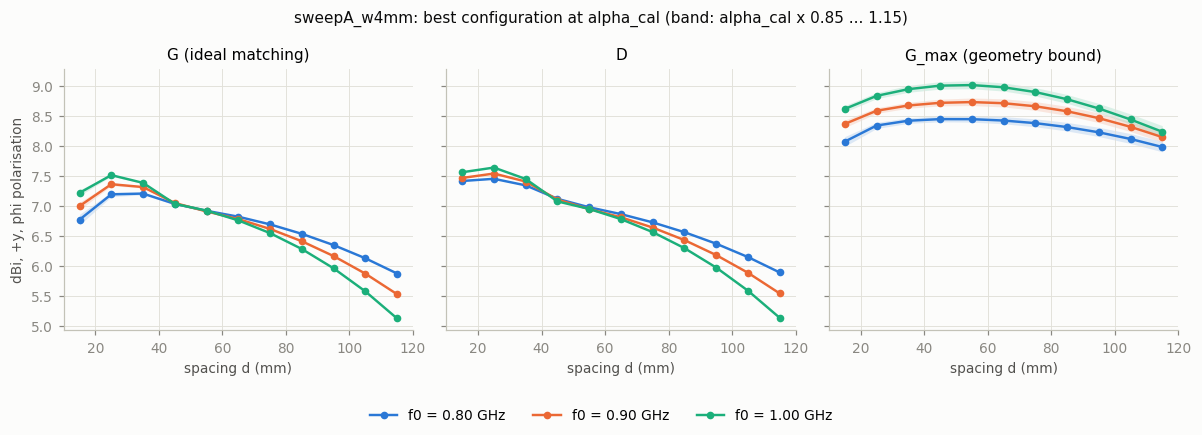

In [2]:
for tag, s in sweeps.items():
    rows = s['rows']
    freqs = sorted({r['f_GHz'] for r in rows})
    factors = sorted({r['alpha_factor'] for r in rows})
    fig, axes = plt.subplots(1, 3, figsize=(11, 3.9), sharey=True)
    for k, f in enumerate(freqs):
        col = SERIES[k % len(SERIES)]
        for ax, key, name in zip(axes, ('G_dBi', 'D_dBi', 'G_max_dBi'), ('G (ideal matching)', 'D', 'G_max (geometry bound)')):
            d, v = best_curve(rows, f, 1.0, key)
            ax.plot(d, v, marker='o', ms=4, color=col, label=f'f0 = {f:.2f} GHz')
            if len(factors) > 1:
                band = [best_curve(rows, f, fa, key)[1] for fa in factors]
                ax.fill_between(d, np.min(band, axis=0), np.max(band, axis=0), color=col, alpha=0.15, lw=0)
            ax.set_title(name)
            ax.set_xlabel('spacing d (mm)')
    axes[0].set_ylabel('dBi, +y, phi polarisation')
    fig.suptitle(f'{tag}: best configuration at alpha_cal (band: alpha_cal x 0.85 ... 1.15)', fontsize=10, color=INK)
    save(fig, f'{tag}_G_D_Gmax_vs_d.png')

saved D:\PhD_Fahdilou_Leat\PUBLICATIONS\7-EurAAP Small Antenna Super-Gain Challenge\exploration\figures\sweepA_w4mm_eta_X_vs_d.png


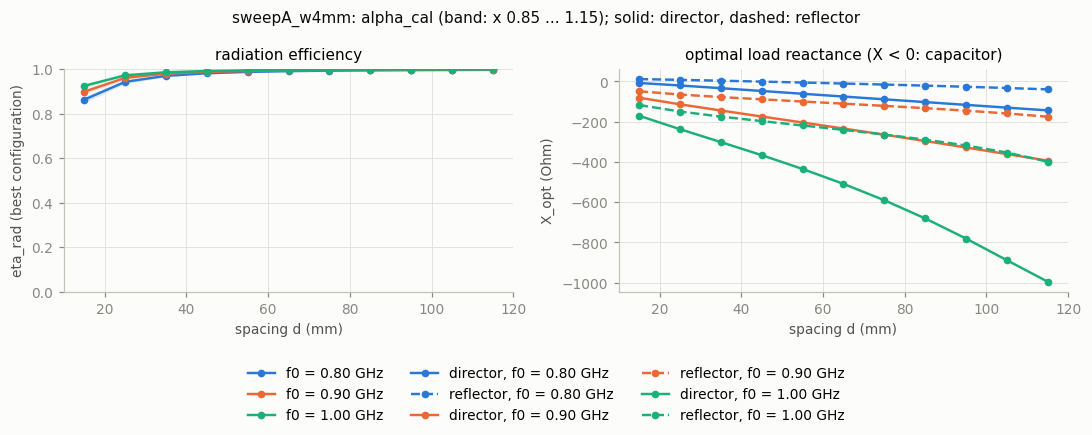

In [3]:
for tag, s in sweeps.items():
    rows = s['rows']
    freqs = sorted({r['f_GHz'] for r in rows})
    factors = sorted({r['alpha_factor'] for r in rows})
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.9))
    for k, f in enumerate(freqs):
        col = SERIES[k % len(SERIES)]
        d, eta = best_curve(rows, f, 1.0, 'eta_rad')
        axes[0].plot(d, eta, marker='o', ms=4, color=col, label=f'f0 = {f:.2f} GHz')
        if len(factors) > 1:
            band = [best_curve(rows, f, fa, 'eta_rad')[1] for fa in factors]
            axes[0].fill_between(d, np.min(band, axis=0), np.max(band, axis=0), color=col, alpha=0.15, lw=0)
        for config, ls in (('director', '-'), ('reflector', '--')):
            pts = sorted((r['spacing_mm'], r['X_opt_ohm']) for r in select(rows, f_GHz=f, alpha_factor=1.0, config=config))
            if pts:
                axes[1].plot(*zip(*pts), marker='o', ms=4, color=col, ls=ls, label=f'{config}, f0 = {f:.2f} GHz')
    axes[0].set_ylabel('eta_rad (best configuration)')
    axes[0].set_ylim(0, 1)
    axes[0].set_title('radiation efficiency')
    axes[1].set_ylabel('X_opt (Ohm)')
    axes[1].set_title('optimal load reactance (X < 0: capacitor)')
    for ax in axes:
        ax.set_xlabel('spacing d (mm)')
    fig.suptitle(f'{tag}: alpha_cal (band: x 0.85 ... 1.15); solid: director, dashed: reflector', fontsize=10, color=INK)
    save(fig, f'{tag}_eta_X_vs_d.png')

saved D:\PhD_Fahdilou_Leat\PUBLICATIONS\7-EurAAP Small Antenna Super-Gain Challenge\exploration\figures\sweepA_w4mm_G_vs_f.png


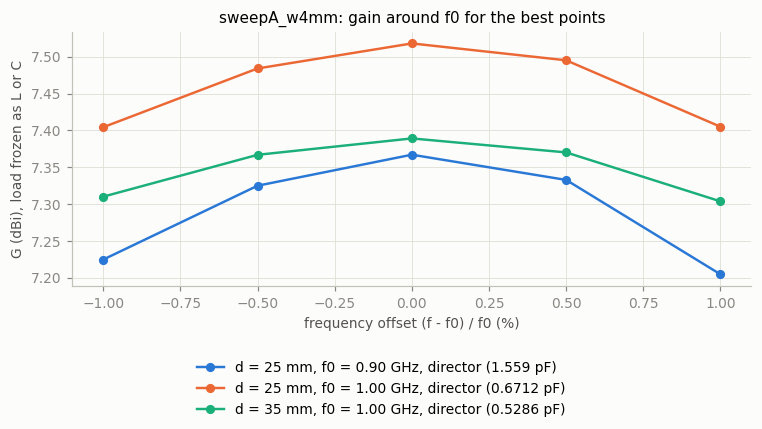

In [4]:
for tag, s in sweeps.items():
    if not s['sens']:
        continue
    fig, ax = plt.subplots(figsize=(7, 3.9))
    points = sorted({(r['spacing_mm'], r['f0_GHz'], r['config']) for r in s['sens']})
    for k, (d, f0, config) in enumerate(points):
        pts = sorted((r['f_over_f0'], r['G_dBi']) for r in s['sens']
                     if r['spacing_mm'] == d and r['f0_GHz'] == f0 and r['config'] == config)
        lab = next(r['element_label'] for r in s['sens'] if r['spacing_mm'] == d and r['f0_GHz'] == f0)
        ax.plot([100 * (x - 1) for x, _ in pts], [g for _, g in pts], marker='o', ms=5,
                color=SERIES[k % len(SERIES)], label=f'd = {d:g} mm, f0 = {f0:.2f} GHz, {config} ({lab})')
    ax.set_xlabel('frequency offset (f - f0) / f0 (%)')
    ax.set_ylabel('G (dBi), load frozen as L or C')
    ax.set_title(f'{tag}: gain around f0 for the best points')
    save(fig, f'{tag}_G_vs_f.png', ncol=1)

In [5]:
for tag, s in sweeps.items():
    best = sorted(select(s['rows'], alpha_factor=1.0, best_config=True), key=lambda r: -r['G'])[:8]
    print(f"{tag} - best points at alpha_cal = {s['meta'].get('alpha_cal', float('nan')):.3f}")
    print(f"{'d':>5s} {'f0':>5s} {'config':>9s} {'G':>6s} {'G_r':>6s} {'D':>6s} {'eta':>6s} {'F/B':>5s} {'G/Gmax':>6s} {'load':>10s}  Zin")
    for r in best:
        print(f"{r['spacing_mm']:5.0f} {r['f_GHz']:5.2f} {r['config']:>9s} {r['G_dBi']:6.2f} {r['G_r_dBi']:6.2f} {r['D_dBi']:6.2f} "
              f"{r['eta_rad']:6.3f} {r['FB_dB']:5.1f} {r['G_over_G_max']:6.3f} {r['element_label']:>10s}  "
              f"{r['Zin_re_ohm']:.1f}{r['Zin_im_ohm']:+.1f}j Ohm")

sweepA_w4mm - best points at alpha_cal = 1.090
    d    f0    config      G    G_r      D    eta   F/B G/Gmax       load  Zin
   25  1.00  director   7.52   0.31   7.64  0.971   7.8  0.738  0.6712 pF  28.6+154.6j Ohm
   35  1.00  director   7.39   1.11   7.45  0.985   7.0  0.698  0.5286 pF  53.8+186.8j Ohm
   25  0.90  director   7.37   2.65   7.54  0.960   7.9  0.755   1.559 pF  14.8+67.4j Ohm
   35  0.90  director   7.32   3.53   7.41  0.979   7.3  0.732   1.226 pF  27.1+83.8j Ohm
   15  1.00  director   7.22  -2.00   7.57  0.924   7.3  0.725  0.9344 pF  10.5+118.0j Ohm
   35  0.80  director   7.21   5.54   7.35  0.969   7.4  0.756   5.965 pF  13.9-0.8j Ohm
   25  0.80  director   7.20   3.80   7.46  0.942   8.2  0.768   10.04 pF  7.7-6.8j Ohm
   45  0.90  director   7.05   3.61   7.11  0.987   6.0  0.681   1.016 pF  41.3+99.5j Ohm
